# Interest rates and covariance

The intermediate calculations were executed; this reading edition adds retrospective explanation. Historical evaluation blocks were reused; they are not fresh holdouts.

Read the saved outputs without executing this notebook. Original code cells, their metadata, execution counts and outputs are preserved. This package supplies selected scientific evidence and context; the code retains its original source environment and frozen-input dependencies. It is not a standalone reproduction environment. See the [notebook index](README.md).

The saved source calls the intermediate scientific modules. Inspect the [method reference](../method-reference/calibration-covariance/README.md) for their numerical definitions and unsupplied dependencies.


## Research question: Rates and portfolio covariance


The original SMH addition helped some portfolios and hurt the broad snapshot portfolio once within-industry residual covariance was retained. The covariance-accounting comparison (RI3) investigates the cross-industry offsets behind that pattern; the Treasury-control comparison (adapted H7) asks whether 10-year Treasury exposure changes the incremental information attributed to SMH.


Read from purpose through methods, checks, results and interpretation. The source calculation uses `quiet_index_500.expansions.covariance` and displays its saved numerical evidence and figures. The saved numerical outputs and retrospective explanation should be read together.


## 1. Purpose and competing explanations


This notebook separates a covariance accounting identity from the reliability of its forecast. Opposing industry exposures can lower estimated portfolio risk; that is useful only if it improves the forecast of subsequently realized variance.

The main alternatives are stale factor-variance levels, changing loadings, changing cross-industry residual dependence and an omitted rate exposure. Rates are a statistical control; a favorable result cannot by itself establish a monetary-policy or discount-rate mechanism.


## 2. Inputs, holdings and paired sample


Use accepted security-level excess returns, F, z, SMH, snapshot weights and fixed GICS industry groups. The company measurement panel is not a substitute for the share-class-level portfolio inputs.

Compare F, F + SMH, F + z and F + z + SMH using the same eligible securities and daily estimation dates for each four-model comparison. Portfolio-specific common masks may differ, so comparisons between portfolios are not controlled changes of holdings alone.


In [1]:
from pathlib import Path
import os
import sys

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
assert (root / "src" / "quiet_index_500").exists(), "Run from the repository or notebooks directory."
os.environ.setdefault("MPLCONFIGDIR", "/private/tmp/quiet-index-500-matplotlib")
if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))

import pandas as pd
from IPython.display import Image, display
from quiet_index_500.expansions import covariance as component
from quiet_index_500.expansions import common, settings as cfg

component_id = "08"

def show_table(name, columns=None, query=None, n=12):
    frame = common.read(component_id, name)
    if query is not None:
        frame = frame.query(query)
    if columns is not None:
        frame = frame[columns]
    print(f"{name}.csv — showing {min(n, len(frame))} of {len(frame)} rows")
    display(frame.head(n))

def show_figure(name):
    display(Image(filename=str(cfg.result_root / component_id / (name + ".png"))))

def show_inventory():
    records = []
    for path in sorted((cfg.result_root / component_id).glob("*.csv")):
        records.append({"table": path.name, "rows": len(pd.read_csv(path)),
                        "manifest": path.with_suffix(".manifest.json").name})
    display(pd.DataFrame(records))

for variant in cfg.variants:
    component.run(variant)
print("Component calculations and figures saved. Interpretation reserved for the staged review.")


Component calculations and figures saved. Interpretation reserved for the staged review.


In [2]:
# Evidence for analysis: prepare_matched_portfolio_model_inputs
show_table("eligibility_main", n=16)


eligibility_main.csv — showing 16 of 136 rows


,formation_date,variant,portfolio,block,reason,holdings,training_n,future_n,represented_snapshot_weight,omitted_training_dates,omitted_future_dates
0,2017-12-29,main,snapshot,development,eligible,461,488,61,0.954222,2016-01-06|2016-01-07|2016-07-21|2016-07-22|20...,NaN
1,2017-12-29,main,equal,development,eligible,461,488,61,0.954222,2016-01-06|2016-01-07|2016-07-21|2016-07-22|20...,NaN
2,2017-12-29,main,low_smh,development,eligible,231,494,61,0.335411,2016-07-21|2016-07-22|2016-10-10|2016-10-11|20...,NaN
3,2017-12-29,main,high_smh,development,eligible,230,492,61,0.618811,2016-01-06|2016-01-07|2016-10-10|2016-10-11|20...,NaN
4,2018-03-29,main,snapshot,development,insufficient_common_training_dates,463,394,62,0.956940,2016-03-31|2016-04-01|2016-04-04|2016-04-05|20...,2018-06-08|2018-06-11
5,2018-03-29,main,equal,development,insufficient_common_training_dates,463,394,62,0.956940,2016-03-31|2016-04-01|2016-04-04|2016-04-05|20...,2018-06-08|2018-06-11
6,2018-03-29,main,low_smh,development,eligible,232,494,62,0.292913,2016-07-21|2016-07-22|2016-10-10|2016-10-11|20...,2018-06-08|2018-06-11
7,2018-03-29,main,high_smh,development,insufficient_common_training_dates,231,396,62,0.664027,2016-03-31|2016-04-01|2016-04-04|2016-04-05|20...,2018-06-08|2018-06-11
8,2018-06-29,main,snapshot,development,eligible,464,420,63,0.957602,2016-06-30|2016-07-01|2016-07-05|2016-07-06|20...,NaN
9,2018-06-29,main,equal,development,eligible,464,420,63,0.957602,2016-06-30|2016-07-01|2016-07-05|2016-07-06|20...,NaN


### 2.1 Portfolio definitions and future weights


The primary portfolio is eligible snapshot-weighted holdings. Supporting portfolios are equal-weighted eligible holdings and higher/lower rate-aware SMH-loading halves, split at the formation median. Establish the split once per formation and keep it identical across all four models; document the implementation's tie handling before inspecting results.

Normalize eligible weights once at formation, hold them fixed within the next quarter and use common complete return dates. Require at least 40 such dates. Do not daily-renormalize around missing observations.


In [3]:
# Evidence for analysis: form_fixed_comparison_portfolios
show_table("memberships_main", n=12)
frame = common.read("08", "eligibility_main")
display(frame.groupby(["portfolio", "reason"]).size().rename("formations").reset_index())


memberships_main.csv — showing 12 of 49038 rows


,formation_date,variant,portfolio,block,ticker,weight,group
0,2017-12-29,main,snapshot,development,CMG,0.000643,2530
1,2017-12-29,main,snapshot,development,REGN,0.001182,3520
2,2017-12-29,main,snapshot,development,COR,0.000911,3510
3,2017-12-29,main,snapshot,development,RL,0.000213,2520
4,2017-12-29,main,snapshot,development,TSCO,0.000259,2550
5,2017-12-29,main,snapshot,development,ORLY,0.001098,2550
6,2017-12-29,main,snapshot,development,ABBV,0.007348,3520
7,2017-12-29,main,snapshot,development,NKE,0.000676,2520
8,2017-12-29,main,snapshot,development,TGT,0.001131,3010
9,2017-12-29,main,snapshot,development,KIM,0.000237,6010


,portfolio,reason,formations
0,equal,eligible,31
1,equal,insufficient_common_training_dates,3
2,high_smh,eligible,33
3,high_smh,insufficient_common_training_dates,1
4,low_smh,eligible,34
5,snapshot,eligible,31
6,snapshot,insufficient_common_training_dates,3


## 3. Analysis — factor and residual covariance


Build each covariance estimate as `Sigma = B × factor covariance × B transpose + residual covariance`, with consistent units and sample-covariance denominators. The primary residual model retains covariance within GICS industry groups and sets residual covariance across groups to zero. Diagonal residual covariance is the required benchmark.

Industry groups are not finer GICS industries. Preserve the agreed classification and handling rules rather than searching for a partition that improves the results.


In [4]:
# Evidence for analysis: estimate_matched_factor_and_residual_covariances
show_table("evaluations_main", columns=["formation_date", "portfolio", "model", "residual_treatment", "training_n", "covariance_denominator", "factor_variance", "residual_variance", "predicted_variance"], n=16)


evaluations_main.csv — showing 16 of 1032 rows


,formation_date,portfolio,model,residual_treatment,training_n,covariance_denominator,factor_variance,residual_variance,predicted_variance
0,2017-12-29,snapshot,F,industry_block,488,487,0.015566,0.002198,0.017764
1,2017-12-29,snapshot,F,diagonal,488,487,0.015566,0.001445,0.017011
2,2017-12-29,snapshot,FS,industry_block,488,487,0.016538,0.001384,0.017922
3,2017-12-29,snapshot,FS,diagonal,488,487,0.016538,0.001219,0.017757
4,2017-12-29,snapshot,FZ,industry_block,488,487,0.015566,0.002191,0.017757
5,2017-12-29,snapshot,FZ,diagonal,488,487,0.015566,0.001443,0.017009
6,2017-12-29,snapshot,FZS,industry_block,488,487,0.016539,0.001379,0.017917
7,2017-12-29,snapshot,FZS,diagonal,488,487,0.016539,0.001217,0.017755
8,2017-12-29,equal,F,industry_block,488,487,0.012557,0.000373,0.012930
9,2017-12-29,equal,F,diagonal,488,487,0.012557,0.000093,0.012650


## 4. Treasury-control comparison (adapted H7)


Define `G_equity = loss(F) − loss(F + SMH)` and `G_rates = loss(F + z) − loss(F + z + SMH)`. The primary endpoint is `G_equity − G_rates` for the industry-aware snapshot-weighted portfolio; a positive difference means the measured SMH increment shrank after rates entered.

Report whether rates themselves improve the baseline and whether either SMH increment is positive. Only describe attenuation of an advantage when G_equity is positive. The inherited descriptive threshold for material attenuation is a reduction of at least half. TLT is not included in any main or sensitivity fit.


In [5]:
# Evidence for analysis: score_rate_and_semiconductor_covariance_increments
show_table("summary_main", query="portfolio == 'snapshot' and residual_treatment == 'industry_block'", n=12)
show_table("quarters_main", query="portfolio == 'snapshot' and residual_treatment == 'industry_block' and block != 'development'", n=14)


summary_main.csv — showing 3 of 3 rows


,comparison,variant,portfolio,residual_treatment,block,effect,ci_low,ci_high,p_two_sided,quarters,calendar_quarters,missing_quarters,mean_G_equity,mean_G_rates,mean_rate_baseline_improvement,original_advantage_present,material_attenuation
21,H7_rates,main,snapshot,industry_block,development,-0.000055,-0.000250,0.000058,0.532734,17,20,3,-0.000462,-0.000408,0.000030,False,False
22,H7_rates,main,snapshot,industry_block,historical_late,-0.000050,-0.000290,0.000162,0.501249,6,6,0,-0.017086,-0.017036,-0.000139,False,False
23,H7_rates,main,snapshot,industry_block,historical_validation,-0.000018,-0.000034,-0.000002,0.000500,8,8,0,0.003345,0.003364,0.000039,True,False


quarters_main.csv — showing 14 of 14 rows


,formation_date,block,portfolio,residual_treatment,variant,controls,comparison,improvement,G_equity,G_rates,rate_baseline_improvement,material_attenuation,original_advantage_present
153,2022-12-30,historical_validation,snapshot,industry_block,main,industry_block,H7_rates,-0.000018,0.000919,0.000937,0.000020,False,True
161,2023-03-31,historical_validation,snapshot,industry_block,main,industry_block,H7_rates,-0.000039,0.002288,0.002327,0.000056,False,True
169,2023-06-30,historical_validation,snapshot,industry_block,main,industry_block,H7_rates,-0.000048,0.003278,0.003326,0.000021,False,True
177,2023-09-29,historical_validation,snapshot,industry_block,main,industry_block,H7_rates,-0.000037,0.003407,0.003444,0.000029,False,True
185,2023-12-29,historical_validation,snapshot,industry_block,main,industry_block,H7_rates,-0.000005,0.003514,0.003520,0.000060,False,True
193,2024-03-28,historical_validation,snapshot,industry_block,main,industry_block,H7_rates,-0.000006,0.005525,0.005531,0.000076,False,True
201,2024-06-28,historical_validation,snapshot,industry_block,main,industry_block,H7_rates,0.000003,-0.000613,-0.000616,-0.000004,False,False
209,2024-09-30,historical_validation,snapshot,industry_block,main,industry_block,H7_rates,0.000007,0.008445,0.008438,0.000050,False,True
217,2024-12-31,historical_late,snapshot,industry_block,main,industry_block,H7_rates,-0.000162,-0.022198,-0.022036,-0.000273,False,False
225,2025-03-31,historical_late,snapshot,industry_block,main,industry_block,H7_rates,-0.000807,-0.121769,-0.120961,-0.001553,False,False


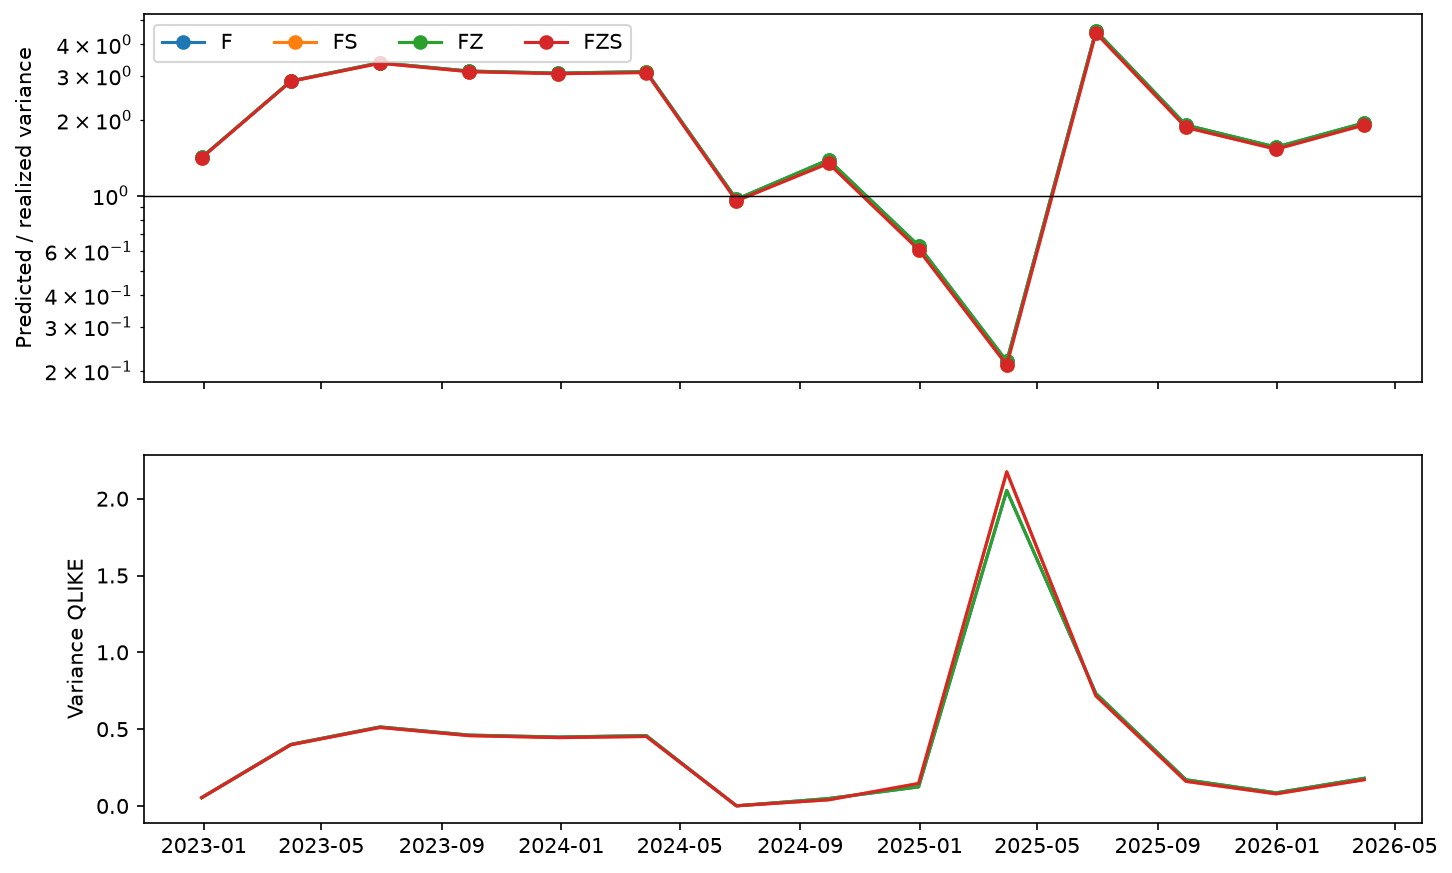

In [6]:
# Evidence for visualization: plot_portfolio_forecasts_and_rate_increments
show_figure("broad_portfolio_forecast_accuracy")


**Interpretation.** For the primary snapshot/industry-block case, SMH gain before rates is 0.003345 / −0.017086 in validation/late, and after rates 0.003364 / −0.017036. Rates barely alter the pattern; the H7 difference is negative, not attenuation of a positive advantage. Late there is no positive original advantage to attenuate. See primary-filter source rows.


## 5. Covariance accounting (RI3)


For the rate-aware comparison, let u be SMH projected on F and z on the portfolio's common dates; for the equity-only comparison, project on F. Let g_k be the portfolio-weighted sum of the corresponding SMH loadings in industry group k.

Under the industry-block model, the exact addition to estimated variance is `Var(u) × [(sum g_k)^2 − sum(g_k^2)]`, with consistent annualization. The diagonal benchmark uses the corresponding subtraction at the individual-security level. This explains the sign of the fitted adjustment, not its persistence into the next quarter.


In [7]:
# Evidence for validation: reconcile_semiconductor_covariance_identity
checks = common.read("08", "identity_checks_main")
print("Maximum variance-identity discrepancy:", checks.identity_error.max())
display(checks.head(12))


Maximum variance-identity discrepancy: 5.52444374968e-15


,formation_date,variant,portfolio,block,baseline_model,extension_model,residual_treatment,direct_variance_change,analytical_variance_change,identity_error,training_u_variance,portfolio_loading
0,2017-12-29,main,snapshot,development,F,FS,industry_block,0.000157,0.000157,2.770137e-17,0.013272,0.270574
1,2017-12-29,main,snapshot,development,F,FS,diagonal,0.000745,0.000745,2.157562e-17,0.013272,0.270574
2,2017-12-29,main,snapshot,development,FZ,FZS,industry_block,0.000160,0.000160,2.806701e-15,0.013261,0.270775
3,2017-12-29,main,snapshot,development,FZ,FZS,diagonal,0.000746,0.000746,2.811228e-15,0.013261,0.270775
4,2017-12-29,main,equal,development,F,FS,industry_block,-0.000018,-0.000018,3.513493e-18,0.013272,0.033595
5,2017-12-29,main,equal,development,F,FS,diagonal,0.000013,0.000013,5.565006e-18,0.013272,0.033595
6,2017-12-29,main,equal,development,FZ,FZS,industry_block,-0.000017,-0.000017,2.637318e-15,0.013261,0.034324
7,2017-12-29,main,equal,development,FZ,FZS,diagonal,0.000013,0.000013,2.640342e-15,0.013261,0.034324
8,2017-12-29,main,low_smh,development,F,FS,industry_block,0.000198,0.000198,6.776264e-19,0.013324,-0.130417
9,2017-12-29,main,low_smh,development,F,FS,diagonal,0.000221,0.000221,6.234162e-19,0.013324,-0.130417


**Reading the identity check.** Near-zero discrepancy means the direct covariance change matches the analytic expression. The units are annualized variance; neither the discrepancy nor the expression is QLIKE or a forecast-gain attribution.


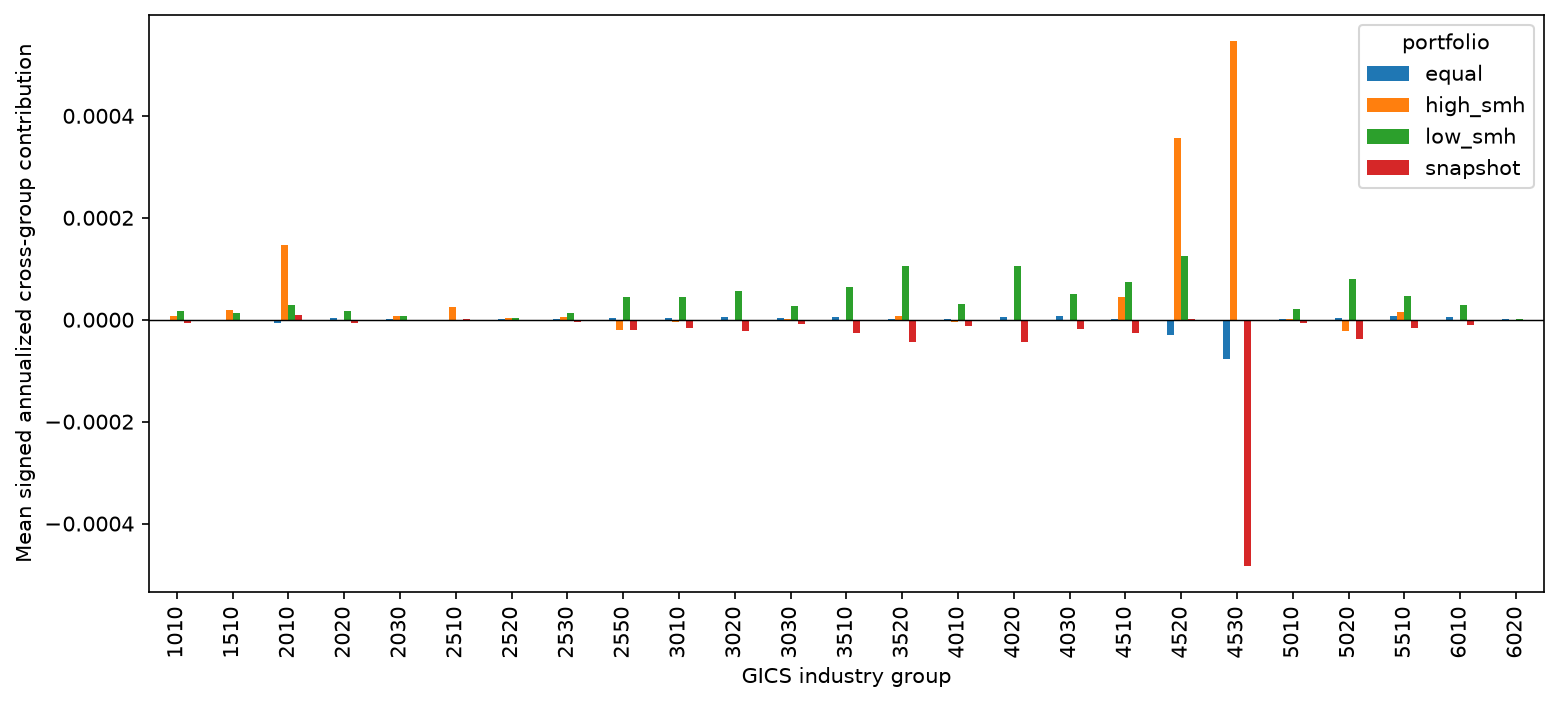

In [8]:
# Evidence for visualization: plot_signed_industry_covariance_contributions
show_figure("signed_industry_covariance_contributions")


### 5.1 Distinguish variance level from dependence changes


Compare formation predictions with subsequent orthogonal-SMH variation, loading behavior and cross-group residual covariance. These future measurements are hindsight explanations, not inputs to the scored forecast.

The aim is to determine how far the observed error can be attributed to factor-variance levels versus dependence or loading changes. The diagnostics may leave the mechanism unresolved. They do not authorize a tuned stress threshold, a new covariance shrinkage rule or evaluation-period refits in the production forecast.


In [9]:
# Evidence for analysis: diagnose_covariance_forecast_errors
show_table("hindsight_diagnostics_main", query="portfolio == 'snapshot' and baseline_model == 'FZ' and block != 'development'", n=14)


hindsight_diagnostics_main.csv — showing 14 of 14 rows


,formation_date,variant,portfolio,block,baseline_model,diagnostic_future_n,training_u_variance,future_u_variance,frozen_portfolio_loading,future_refitted_portfolio_loading,future_cross_group_frozen_residual_covariance,frozen_loading_adjustment_at_future_u_variance,hindsight_only
147,2022-12-30,main,snapshot,historical_validation,FZ,62,0.026815,0.034636,0.192810,0.175595,-0.000733,-0.000255,True
155,2023-03-31,main,snapshot,historical_validation,FZ,62,0.028762,0.041677,0.198082,0.165978,-0.000608,-0.000349,True
163,2023-06-30,main,snapshot,historical_validation,FZ,63,0.030164,0.021393,0.201224,0.157358,-0.000690,-0.000207,True
171,2023-09-29,main,snapshot,historical_validation,FZ,61,0.031028,0.017421,0.199869,0.144301,-0.000606,-0.000185,True
179,2023-12-29,main,snapshot,historical_validation,FZ,61,0.029228,0.034531,0.196308,0.103395,-0.000456,-0.000367,True
187,2024-03-28,main,snapshot,historical_validation,FZ,63,0.029246,0.027009,0.184508,0.093197,-0.000833,-0.000395,True
195,2024-06-28,main,snapshot,historical_validation,FZ,64,0.028135,0.115966,0.164086,0.102385,-0.001037,-0.002358,True
203,2024-09-30,main,snapshot,historical_validation,FZ,60,0.032427,0.034357,0.152033,0.107274,-0.000831,-0.000931,True
211,2024-12-31,main,snapshot,historical_late,FZ,60,0.032373,0.041136,0.139793,0.131224,-0.001062,-0.001110,True
219,2025-03-31,main,snapshot,historical_late,FZ,62,0.033017,0.031049,0.142327,0.130331,-0.001110,-0.000824,True


**Read the hindsight panel carefully.** Future orthogonal-SMH variance, future refitted loading and future frozen-residual cross-group covariance help describe a miss. They were unavailable at formation and cannot be credited as improvements of the original forecast.


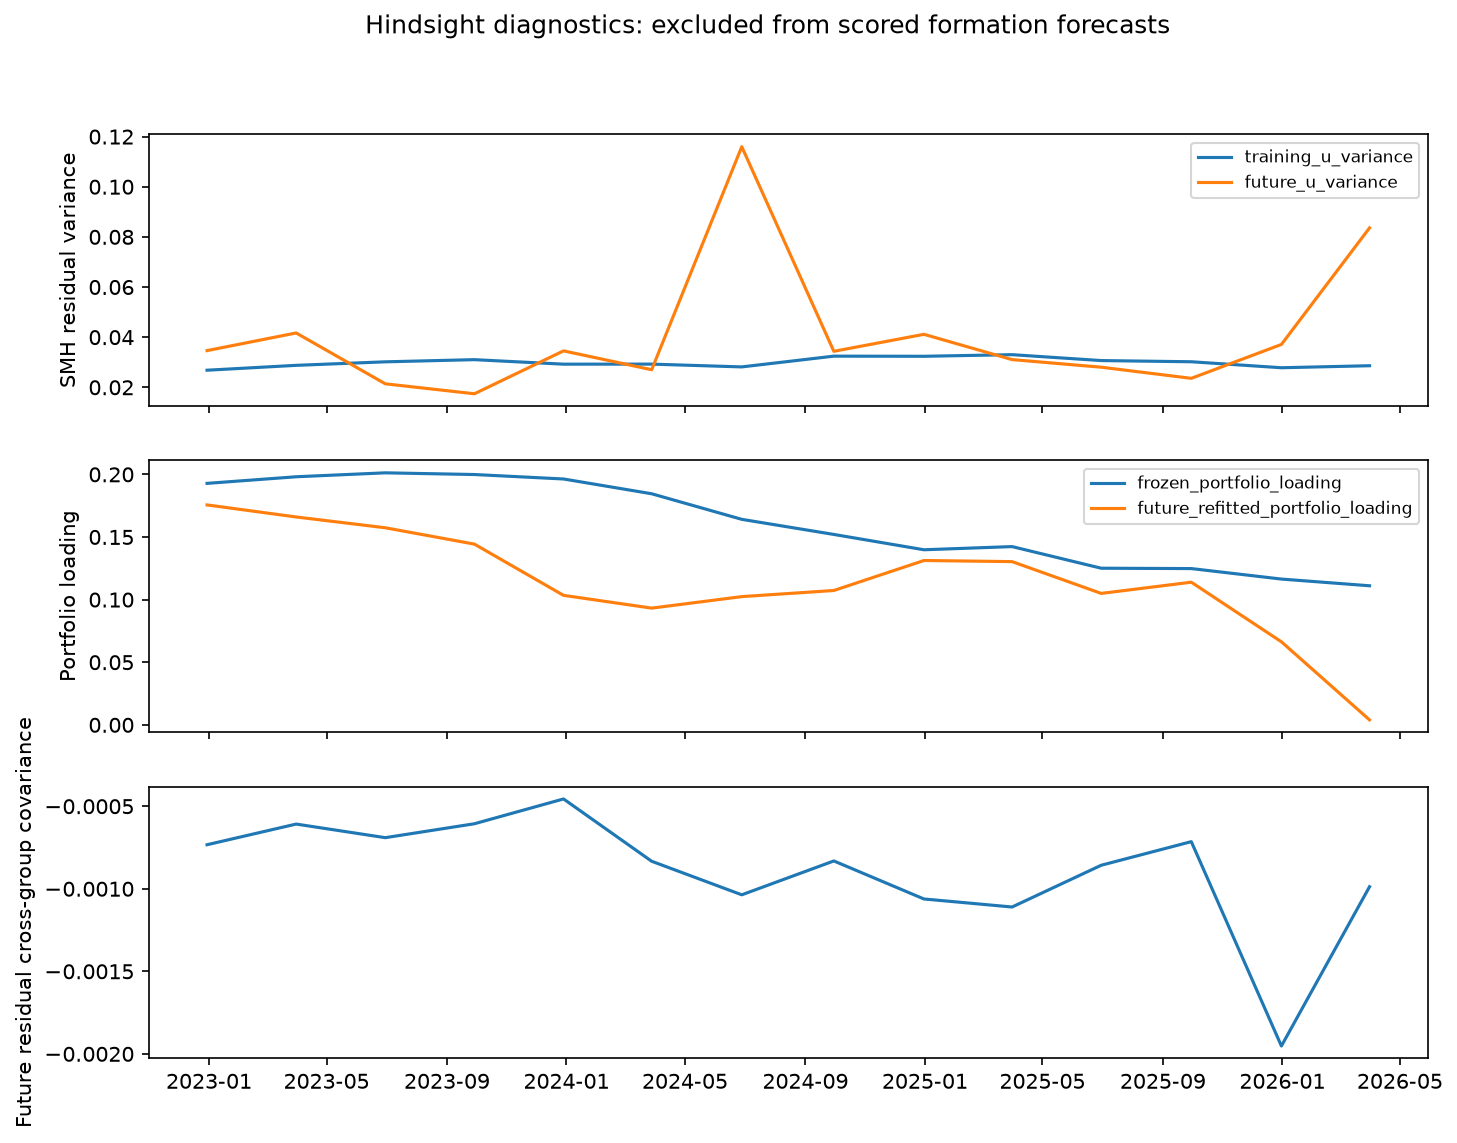

In [10]:
# Evidence for visualization: plot_covariance_error_diagnostics
show_figure("covariance_error_diagnostics")


## 6. Sensitivities and portfolio dependence


Repeat the 252-session window and retain the diagonal-versus-industry-group benchmark. Report all supporting portfolio results and their common-date coverage. Use paired quarter-block uncertainty for the primary adapted-H7 endpoint; the source synthesis records its place in the comparison family.


In [11]:
# Evidence for validation: summarize_covariance_robustness_and_coverage
for variant in cfg.variants:
    show_table("summary_" + variant, query="block != 'development'", n=20)


summary_main.csv — showing 16 of 16 rows


,comparison,variant,portfolio,residual_treatment,block,effect,ci_low,ci_high,p_two_sided,quarters,calendar_quarters,missing_quarters,mean_G_equity,mean_G_rates,mean_rate_baseline_improvement,original_advantage_present,material_attenuation
1,H7_rates,main,equal,diagonal,historical_late,8.073141e-05,-0.000232,0.000434,0.437781,6,6,0,0.000196,0.000115,0.001101,True,False
2,H7_rates,main,equal,diagonal,historical_validation,-1.276964e-05,-0.000022,-0.000004,0.000500,8,8,0,-0.000006,0.000007,-0.000360,False,False
4,H7_rates,main,equal,industry_block,historical_late,-3.866444e-05,-0.000141,0.000084,0.437781,6,6,0,-0.003019,-0.002981,0.000297,False,False
5,H7_rates,main,equal,industry_block,historical_validation,3.428232e-07,-0.000004,0.000005,0.809095,8,8,0,0.000878,0.000877,-0.000192,True,False
7,H7_rates,main,high_smh,diagonal,historical_late,1.130838e-03,-0.000960,0.003186,0.437781,6,6,0,0.055517,0.054386,0.001221,True,False
8,H7_rates,main,high_smh,diagonal,historical_validation,-2.172900e-04,-0.000378,-0.000056,0.000500,8,8,0,-0.015018,-0.014801,-0.000324,False,False
10,H7_rates,main,high_smh,industry_block,historical_late,4.773683e-04,-0.000682,0.001622,0.437781,6,6,0,0.011887,0.011410,0.000550,True,False
11,H7_rates,main,high_smh,industry_block,historical_validation,-1.821938e-04,-0.000306,-0.000058,0.000500,8,8,0,-0.005543,-0.005360,-0.000267,False,False
13,H7_rates,main,low_smh,diagonal,historical_late,1.901391e-03,-0.001737,0.005540,0.437781,6,6,0,0.055538,0.053636,0.002403,True,False
14,H7_rates,main,low_smh,diagonal,historical_validation,-3.720248e-04,-0.000609,-0.000135,0.000500,8,8,0,-0.017771,-0.017399,-0.001228,False,False


summary_window252.csv — showing 16 of 16 rows


,comparison,variant,portfolio,residual_treatment,block,effect,ci_low,ci_high,p_two_sided,quarters,calendar_quarters,missing_quarters,mean_G_equity,mean_G_rates,mean_rate_baseline_improvement,original_advantage_present,material_attenuation
1,H7_rates,window252,equal,diagonal,historical_late,0.000151,-0.000686,0.000989,0.614193,6,6,0,-0.000467,-0.000618,0.002169,False,False
2,H7_rates,window252,equal,diagonal,historical_validation,0.000012,-0.000024,0.000049,0.620190,8,8,0,-0.000105,-0.000117,-0.000318,False,False
4,H7_rates,window252,equal,industry_block,historical_late,-0.000268,-0.000442,-0.000095,0.000500,6,6,0,-0.003636,-0.003368,0.000763,False,False
5,H7_rates,window252,equal,industry_block,historical_validation,0.000030,-0.000007,0.000067,0.129435,8,8,0,0.000403,0.000373,-0.000203,True,False
7,H7_rates,window252,high_smh,diagonal,historical_late,0.000920,-0.003126,0.004966,0.603698,6,6,0,0.027191,0.026271,0.000604,True,False
8,H7_rates,window252,high_smh,diagonal,historical_validation,-0.000280,-0.000510,-0.000050,0.000500,8,8,0,0.004405,0.004685,-0.000462,True,False
10,H7_rates,window252,high_smh,industry_block,historical_late,0.000080,-0.002181,0.002342,0.838081,6,6,0,0.004141,0.004060,-0.000274,True,False
11,H7_rates,window252,high_smh,industry_block,historical_validation,-0.000126,-0.000272,0.000020,0.161919,8,8,0,-0.001553,-0.001427,-0.000247,False,False
13,H7_rates,window252,low_smh,diagonal,historical_late,-0.000988,-0.009278,0.007302,0.774613,6,6,0,0.023544,0.024532,-0.003302,True,False
14,H7_rates,window252,low_smh,diagonal,historical_validation,-0.000115,-0.000403,0.000172,0.523238,8,8,0,-0.006302,-0.006187,-0.000594,False,False


summary_equity_shock.csv — showing 16 of 16 rows


,comparison,variant,portfolio,residual_treatment,block,effect,ci_low,ci_high,p_two_sided,quarters,calendar_quarters,missing_quarters,mean_G_equity,mean_G_rates,mean_rate_baseline_improvement,original_advantage_present,material_attenuation
1,H7_rates,equity_shock,equal,diagonal,historical_late,8.073141e-05,-0.000232,0.000434,0.437781,6,6,0,0.000196,0.000115,0.001101,True,False
2,H7_rates,equity_shock,equal,diagonal,historical_validation,-1.276964e-05,-0.000022,-0.000004,0.000500,8,8,0,-0.000006,0.000007,-0.000360,False,False
4,H7_rates,equity_shock,equal,industry_block,historical_late,-3.866444e-05,-0.000141,0.000084,0.437781,6,6,0,-0.003019,-0.002981,0.000297,False,False
5,H7_rates,equity_shock,equal,industry_block,historical_validation,3.428232e-07,-0.000004,0.000005,0.809095,8,8,0,0.000878,0.000877,-0.000192,True,False
7,H7_rates,equity_shock,high_smh,diagonal,historical_late,1.219310e-03,-0.001008,0.003477,0.437781,6,6,0,0.057717,0.056498,0.001286,True,False
8,H7_rates,equity_shock,high_smh,diagonal,historical_validation,-2.587525e-04,-0.000395,-0.000122,0.000500,8,8,0,-0.015734,-0.015475,-0.000383,False,False
10,H7_rates,equity_shock,high_smh,industry_block,historical_late,5.180134e-04,-0.000761,0.001815,0.437781,6,6,0,0.012816,0.012298,0.000573,True,False
11,H7_rates,equity_shock,high_smh,industry_block,historical_validation,-2.122222e-04,-0.000324,-0.000101,0.000500,8,8,0,-0.005615,-0.005402,-0.000315,False,False
13,H7_rates,equity_shock,low_smh,diagonal,historical_late,1.590558e-03,-0.002814,0.005905,0.437781,6,6,0,0.051729,0.050138,0.001788,True,False
14,H7_rates,equity_shock,low_smh,diagonal,historical_validation,-4.335727e-04,-0.000738,-0.000129,0.000500,8,8,0,-0.017886,-0.017452,-0.001595,False,False


## 7. Results — rates, portfolio composition and offsets


### Retrospective findings and explanation

[Reading notebook](interest-rates-and-covariance.ipynb) · All portfolio summaries · Quarter effects · Identity checks · Hindsight diagnostics

**Question and sample.** Why can adding an SMH factor help a concentrated or sorted portfolio but hurt a broad portfolio? Can rates explain the SMH increment? Here the unit is a fixed-weight portfolio of eligible securities, including share classes, rather than one representative observation per issuer. Primary holdings use normalized eligible September 2026 snapshot weights, fixed through the next quarter. Supporting portfolios are equal weights and high/low rate-aware SMH-loading halves; ties use ticker order and the lower half contains the median when the count is odd. Different portfolio masks can select different dates, so their results are not a controlled holdings-only experiment.

Each four-model comparison holds holdings, estimation dates, future dates and residual treatment fixed: **F**, **FS** (F + SMH), **FZ** (F + rates), **FZS** (F + rates + SMH). At least 40 common future return dates are required. Forecast covariance is factor covariance propagated through loadings plus a residual covariance estimate. The primary residual restriction retains covariance within GICS **industry groups**, setting cross-group residual covariance to zero. The required diagonal sensitivity keeps only individual residual variances. These restrictions concern dependence that a factor may restore, not different factor names for the same full unrestricted covariance matrix.

Define `G_equity = loss(F) − loss(FS)` and `G_rates = loss(FZ) − loss(FZS)`. H7's primary endpoint is **G_equity − G_rates** for snapshot weights with industry-block residual covariance. Positive means the measured SMH increment shrank after controlling rates. To call it attenuation of an advantage, the original G_equity must first be positive. The inherited materiality threshold is at least half of that advantage.

| Primary snapshot/industry-block result | 2023–2024 | 2025–2026 Q2 |
|---|---:|---:|
| Mean SMH gain before rates, G_equity | 0.003345 | −0.017086 |
| Mean SMH gain after rates, G_rates | 0.003364 | −0.017036 |
| Rates themselves: loss(F) − loss(FZ) | 0.0000387 | −0.0001393 |
| H7 difference of gains | −0.00001811 | −0.00004999 |
| Saved H7 95% interval | [−0.00003403, −0.00000218] | [−0.00029002, 0.00016165] |

*Source: summary_main.csv, `portfolio=snapshot`, `residual_treatment=industry_block`, `variant=main`, eight/six evaluation quarters; columns `mean_G_equity`, `mean_G_rates`, `mean_rate_baseline_improvement`, `effect`, `ci_low`, `ci_high`. All entries are absolute QLIKE or differences of QLIKE gains, never percentages.*

Rate adjustment hardly changes the pattern. Validation has a small SMH advantage that grows slightly after rates, the opposite of attenuation. Late SMH is harmful before and after rates, so there is no positive advantage to attenuate there. Rates alone do not robustly improve the primary broad-portfolio baseline: the point change is slightly helpful in validation and adverse late. These comparisons do not support “omitted Treasury exposure explains away the original portfolio puzzle.”

![SMH gain by portfolio and residual restriction](assets/interest-rates-and-covariance-portfolio_dependence.png)

*Source: 08 main summary, all four portfolios × both residual treatments × both evaluation blocks, `mean_G_rates`. Bars are loss(FZ) − loss(FZS), positive means SMH helps after rates. Eight validation and six late quarters; masks may differ by portfolio. No confidence bands are invented for the individual SMH-gain bars. SVG. The primary broad industry-block result differs from the diagonal benchmark and from sorted portfolios; a single overall SMH verdict would erase that dependence.*

**RI3: arithmetic before interpretation.** Let g_k be the portfolio-weighted SMH loading in industry group k and let Var(u) be the matching orthogonal-SMH variance. Adding SMH while imposing industry-block residual covariance changes predicted variance by

`Var(u) × [(sum_k g_k)^2 − sum_k g_k^2]`.

The expression equals twice the sum of pairwise cross-group products. If groups have opposing signed loadings, these products can reduce forecast variance. Under diagonal residual covariance the analogous subtraction occurs at individual security level. This is an exact result under the matched fitted projection and covariance conventions; it does not require that those opposing loadings remain stable next quarter. All **516 main identity rows** reconcile to maximum absolute `identity_error` about **5.52 × 10⁻¹⁵** in annualized variance units. See identity_checks_main.csv, all portfolios, models, periods and residual treatments. That check confirms an implementation identity, not a useful forecast.

A decrease in predicted variance can improve an overprediction or worsen an underprediction; QLIKE additionally depends nonlinearly on the realized/predicted ratio. The covariance expression therefore cannot be divided into “shares of QLIKE loss.” Hindsight diagnostics report future u variance, future refitted loading and future cross-group covariance of frozen residuals. Their columns explicitly mark `hindsight_only=True`. They compare possible contributors to error, but do not enter the forecast and cannot identify a unique causal mechanism. Later integration's separate error accounting strengthens this distinction; it does not make the original identity an attribution of loss.

**Contrary evidence and limits.** The diagonal benchmark and high/low halves can favor SMH while the primary broad industry-block model disfavors it late. The 252-session snapshot/industry-block mean G_equity changes to **−0.000030 / −0.010333**, and G_rates to **0.000025 / −0.010249** in validation/late; the H7 endpoint stays slightly negative in both. Thus even the small validation advantage is sensitive to exposure window, while rate control does not resolve the problem. See 252-session summary, matching snapshot/industry-block filters. There are no new fits or tuned stress cutoffs in this reading edition.

**What follows.** Portfolio dependence is a separate objective from company risk prediction. Rates, covariance restrictions, frozen loadings and future common variation have to be distinguished. The source diagnostics permit describing these alternatives, but not declaring cross-industry offsets the unique empirical cause of every miss. The [synthesis](../FINDINGS.md) brings the company and portfolio findings together while keeping their targets and metrics distinct.


## Takeaways and limits


**Interpretation.** Rates do not explain away the portfolio dependence. The identity precisely describes how the restricted covariance estimate moves, while forecasting value depends on future variance and dependence. Saved future-u/loadings/cross-group residual diagnostics are hindsight only, not production inputs or causal attribution. Never divide those variance terms into shares of QLIKE loss.


## Related evidence

The [findings and synthesis](../FINDINGS.md) reconcile these results with the other company and portfolio comparisons. Source comparison identifiers remain in the saved outputs for traceability.


Pass the primary adapted-H7 quarterly effects, covariance reconciliation, portfolio coverage and RI3 evidence to notebook 10. Keep the original and rate-aware shock definitions distinguishable in saved artifacts.


In [12]:
# Evidence for artifact: save_notebook_evidence
show_inventory()


,table,rows,manifest
0,eligibility_equity_shock.csv,136,eligibility_equity_shock.manifest.json
1,eligibility_main.csv,136,eligibility_main.manifest.json
2,eligibility_window252.csv,136,eligibility_window252.manifest.json
3,evaluations_equity_shock.csv,1032,evaluations_equity_shock.manifest.json
4,evaluations_main.csv,1032,evaluations_main.manifest.json
5,evaluations_window252.csv,1048,evaluations_window252.manifest.json
6,group_contributions_equity_shock.csv,6166,group_contributions_equity_shock.manifest.json
7,group_contributions_main.csv,6170,group_contributions_main.manifest.json
8,group_contributions_window252.csv,6292,group_contributions_window252.manifest.json
9,hindsight_diagnostics_equity_shock.csv,258,hindsight_diagnostics_equity_shock.manifest.json
